# Profit-Driven Bank Customer Churn Prediction & CASA Retention Optimization

Notebook ini membangun model probabilitas churn nasabah bank, lalu menggabungkannya dengan nilai ekonomi tiap nasabah untuk menentukan siapa yang layak diberi insentif retensi.

**Alur:** (1) Cleaning & split → (2) EDA 3 hipotesis bisnis → (3) Feature engineering → (4) Modeling & kalibrasi → (5) SHAP → (6) Simulasi profit & sensitivitas.

Ringkasan hasil dan keterbatasan ada di README repository.


# Load Dataset

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

URL = "https://raw.githubusercontent.com/sharmaroshan/Churn-Modelling-Dataset/master/Churn_Modelling.csv"
df = pd.read_csv(URL)

print("Ukuran data:", df.shape)
df.head()

Ukuran data: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Cek Missing Values

In [43]:
import os
os.makedirs('images', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

def save_fig(name):
    plt.savefig(f'images/{name}.png', dpi=150, bbox_inches='tight')

In [6]:
df.info()
print("\nMissing value per kolom:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
Credi

Cek Duplikat

In [7]:
print("Duplikat baris penuh :", df.duplicated().sum())
print("Duplikat CustomerId  :", df['CustomerId'].duplicated().sum())

print("\nProporsi Exited:")
print(df['Exited'].value_counts(normalize=True).round(4))

print("\nProporsi nasabah Balance = 0:", round((df['Balance'] == 0).mean(), 4))

Duplikat baris penuh : 0
Duplikat CustomerId  : 0

Proporsi Exited:
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

Proporsi nasabah Balance = 0: 0.3617


Statistik Deskriptif

In [8]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48


Cek Nilai Ekstrim

In [9]:
print("Salary < 1.000      :", (df['EstimatedSalary'] < 1000).sum())
print("Salary < 10.000     :", (df['EstimatedSalary'] < 10000).sum())
print("Age > 80            :", (df['Age'] > 80).sum())

# Cek Balance_to_Salary sementara (belum jadi fitur, hanya untuk lihat skala)
bts = df['Balance'] / (df['EstimatedSalary'] + 1)
print("\nBalance_to_Salary (preview):")
print(bts.describe(percentiles=[.5, .9, .99]).round(2))

Salary < 1.000      : 59
Salary < 10.000     : 508
Age > 80            : 12

Balance_to_Salary (preview):
count    10000.00
mean         3.79
std        100.06
min          0.00
50%          0.75
90%          3.67
99%         35.48
max       9770.88
dtype: float64


Buang kolom non-prediktif & Split Data

In [11]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y = df['Exited']
ids = df['CustomerId']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 4))
print("Churn rate test :", round(y_test.mean(), 4))

Train: (8000, 10) | Test: (2000, 10)
Churn rate train: 0.2037
Churn rate test : 0.2035


In [12]:
train_df = X_train.copy()
train_df['Exited'] = y_train
train_df.shape

(8000, 11)

## Hipotesis 1: Zero-Balance vs High-Balance

Pertanyaan bisnisnya: siapa yang lebih banyak churn, nasabah rekening transit (saldo 0) atau nasabah penyimpan dana? Lalu negara mana yang attrition-nya paling tinggi?

In [13]:
overall_churn = train_df['Exited'].mean()

train_df['Balance_Group'] = np.where(train_df['Balance'] == 0, 'Zero Balance', 'Has Balance')

h1 = train_df.groupby('Balance_Group').agg(
    jumlah_nasabah=('Exited', 'size'),
    churn_rate=('Exited', 'mean'),
    rata2_saldo=('Balance', 'mean')
).round(4)
h1

,jumlah_nasabah,churn_rate,rata2_saldo
Balance_Group,,,
Has Balance,5109,0.2421,119602.5954
Zero Balance,2891,0.1359,0.0000


Pecah nasabah bersaldo jadi 4 kelompok

In [14]:
has_bal = train_df[train_df['Balance'] > 0].copy()
has_bal['Balance_Quartile'] = pd.qcut(
    has_bal['Balance'], q=4,
    labels=['Q1 (terendah)', 'Q2', 'Q3', 'Q4 (tertinggi)']
)

h1b = has_bal.groupby('Balance_Quartile', observed=True).agg(
    jumlah_nasabah=('Exited', 'size'),
    saldo_min=('Balance', 'min'),
    saldo_max=('Balance', 'max'),
    churn_rate=('Exited', 'mean')
).round(4)
h1b

,jumlah_nasabah,saldo_min,saldo_max,churn_rate
Balance_Quartile,,,,
Q1 (terendah),1278,3768.69,99945.93,0.2105
Q2,1277,99948.45,119787.76,0.2749
Q3,1277,119794.67,139064.06,0.2537
Q4 (tertinggi),1277,139070.51,238387.56,0.2294


In [15]:
h1c = train_df.groupby('Geography').agg(
    jumlah_nasabah=('Exited', 'size'),
    churn_rate=('Exited', 'mean'),
    proporsi_saldo_0=('Balance', lambda s: (s == 0).mean()),
    rata2_saldo=('Balance', 'mean')
).round(4).sort_values('churn_rate', ascending=False)
h1c

,jumlah_nasabah,churn_rate,proporsi_saldo_0,rata2_saldo
Geography,,,,
Germany,2005,0.3307,0.0000,119481.5045
Spain,2002,0.1658,0.4800,62300.8240
France,3993,0.1590,0.4833,61798.8965


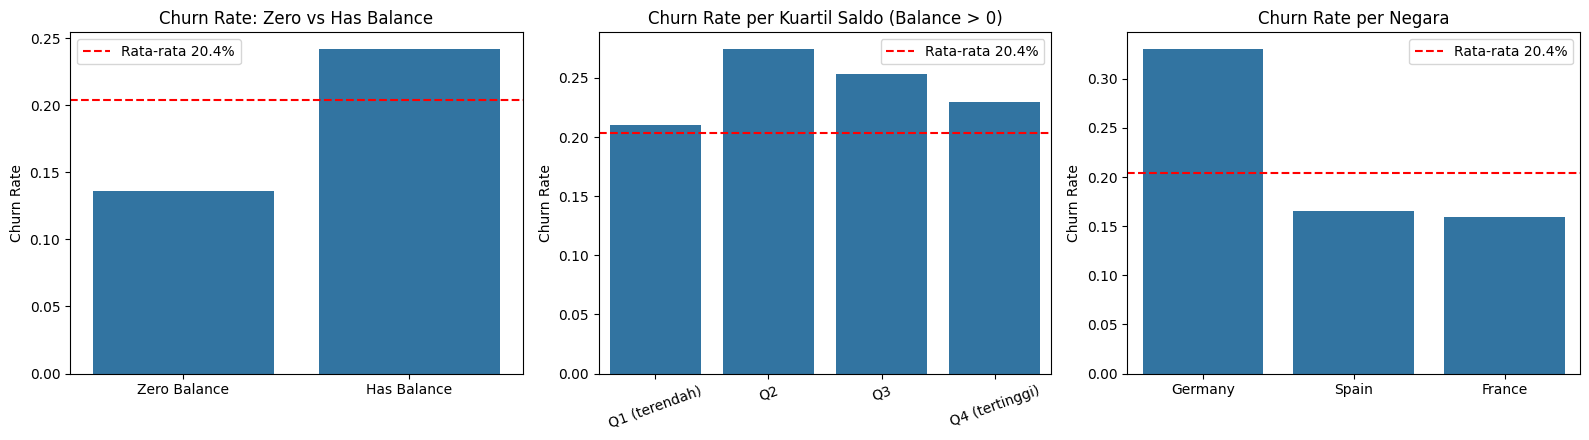

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.barplot(data=train_df, x='Balance_Group', y='Exited', errorbar=None, ax=axes[0])
axes[0].set_title('Churn Rate: Zero vs Has Balance')

sns.barplot(data=has_bal, x='Balance_Quartile', y='Exited', errorbar=None, ax=axes[1])
axes[1].set_title('Churn Rate per Kuartil Saldo (Balance > 0)')
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=train_df, x='Geography', y='Exited', errorbar=None, ax=axes[2],
            order=h1c.index)
axes[2].set_title('Churn Rate per Negara')

for ax in axes:
    ax.axhline(overall_churn, ls='--', color='red', label=f'Rata-rata {overall_churn:.1%}')
    ax.set_ylabel('Churn Rate')
    ax.set_xlabel('')
    ax.legend()

plt.tight_layout()
save_fig('01_eda_balance_geography')
plt.show()

## Hipotesis 1: Ditolak sebagian
Secara agregat, nasabah bersaldo churn 24,2% vs 13,6% pada rekening bersaldo nol. Sebagian selisih ini didorong oleh Jerman (seluruh nasabahnya bersaldo, churn 33,1%). Setelah dikontrol per negara, efeknya tetap ada tetapi lebih kecil, sekitar 5 poin persen di Prancis (18,1% vs 13,5%) dan Spanyol (19,2% vs 13,7%).

Cek confounding

In [17]:
conf = pd.pivot_table(
    train_df, index='Geography', columns='Balance_Group',
    values='Exited', aggfunc=['mean', 'size']
).round(4)
conf

mean                     size             
Balance_Group Has Balance Zero Balance Has Balance Zero Balance
Geography                                                      
France             0.1813       0.1352      2063.0       1930.0
Germany            0.3307          NaN      2005.0          NaN
Spain              0.1921       0.1374      1041.0        961.0

Churn rate per jumlah produk

In [18]:
from statsmodels.stats.proportion import proportion_confint

h2 = train_df.groupby('NumOfProducts').agg(
    jumlah_nasabah=('Exited', 'size'),
    jumlah_churn=('Exited', 'sum'),
    churn_rate=('Exited', 'mean'),
    proporsi_saldo_0=('Balance', lambda s: (s == 0).mean())
)

ci_low, ci_high = proportion_confint(h2['jumlah_churn'], h2['jumlah_nasabah'], method='wilson')
h2['ci95_bawah'] = ci_low
h2['ci95_atas'] = ci_high
h2.round(4)

,jumlah_nasabah,jumlah_churn,churn_rate,proporsi_saldo_0,ci95_bawah,ci95_atas
NumOfProducts,,,,,,
1,4071,1139,0.2798,0.1776,0.2662,0.2938
2,3672,271,0.0738,0.5656,0.0658,0.0827
3,207,170,0.8213,0.3768,0.7634,0.8674
4,50,50,1.0000,0.2600,0.9287,1.0000


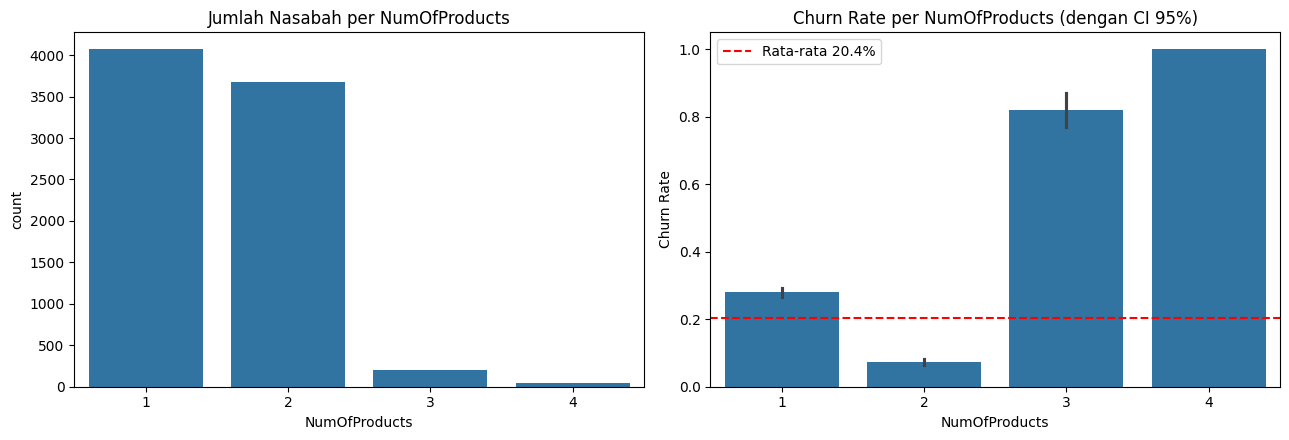

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=train_df, x='NumOfProducts', ax=axes[0])
axes[0].set_title('Jumlah Nasabah per NumOfProducts')

sns.barplot(data=train_df, x='NumOfProducts', y='Exited', errorbar=('ci', 95), ax=axes[1])
axes[1].axhline(overall_churn, ls='--', color='red', label=f'Rata-rata {overall_churn:.1%}')
axes[1].set_title('Churn Rate per NumOfProducts (dengan CI 95%)')
axes[1].set_ylabel('Churn Rate')
axes[1].legend()

plt.tight_layout()
save_fig('02_eda_num_products')
plt.show()

In [20]:
bins = [17, 29, 44, 60, 100]
labels = ['18-29', '30-44', '45-60', '61+']
train_df['Age_Group'] = pd.cut(train_df['Age'], bins=bins, labels=labels)

h3_rate = pd.pivot_table(train_df, index='Age_Group', columns='IsActiveMember',
                         values='Exited', aggfunc='mean', observed=True)
h3_rate.columns = ['Tidak Aktif', 'Aktif']
h3_rate['Selisih (TidakAktif - Aktif)'] = h3_rate['Tidak Aktif'] - h3_rate['Aktif']

h3_n = pd.pivot_table(train_df, index='Age_Group', columns='IsActiveMember',
                      values='Exited', aggfunc='size', observed=True)
h3_n.columns = ['n Tidak Aktif', 'n Aktif']

h3 = pd.concat([h3_rate.round(4), h3_n], axis=1)
h3

,Tidak Aktif,Aktif,Selisih (TidakAktif - Aktif),n Tidak Aktif,n Aktif
Age_Group,,,,,
18-29,0.1042,0.0555,0.0487,643,667
30-44,0.1777,0.1093,0.0684,2442,2388
45-60,0.6560,0.3469,0.3092,721,764
61+,0.8267,0.1033,0.7233,75,300


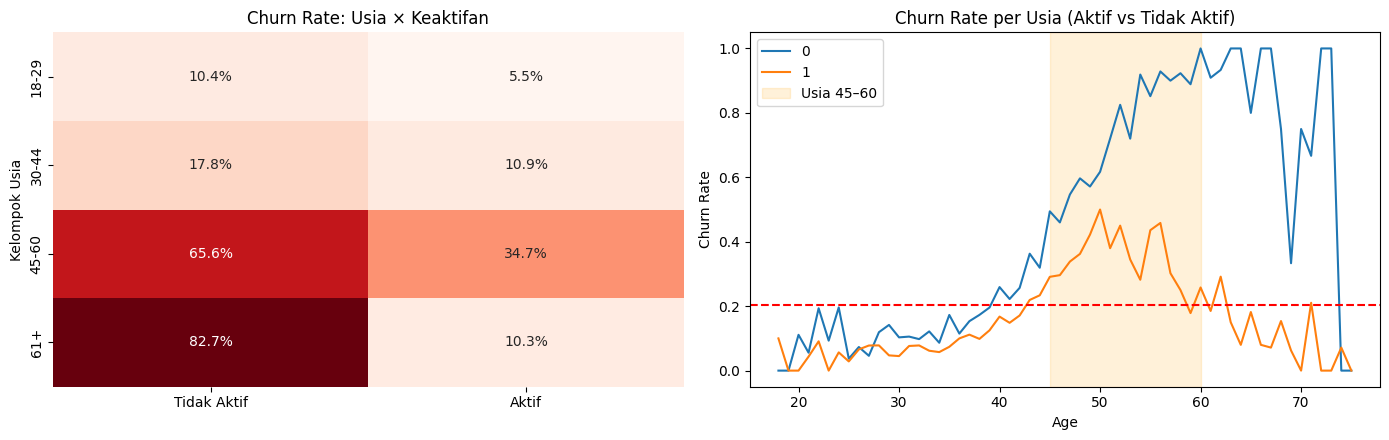

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.heatmap(h3_rate[['Tidak Aktif', 'Aktif']], annot=True, fmt='.1%',
            cmap='Reds', cbar=False, ax=axes[0])
axes[0].set_title('Churn Rate: Usia × Keaktifan')
axes[0].set_ylabel('Kelompok Usia')

age_plot = train_df[train_df['Age'] <= 75]
sns.lineplot(data=age_plot, x='Age', y='Exited', hue='IsActiveMember',
             errorbar=None, ax=axes[1])
axes[1].axvspan(45, 60, alpha=0.15, color='orange', label='Usia 45–60')
axes[1].axhline(overall_churn, ls='--', color='red')
axes[1].set_title('Churn Rate per Usia (Aktif vs Tidak Aktif)')
axes[1].set_ylabel('Churn Rate')
axes[1].legend()

plt.tight_layout()
save_fig('03_eda_age_active')
plt.show()

# Ringkasan EDA
H1: Zero vs High Balance -> Ditolak sebagian. Nasabah bersaldo churn ~5 pp lebih tinggi (setelah dikontrol negara). Jerman paling kritis: churn 33%, saldo rata-rata €119rb

H2: Paradoks produk -> Terbukti. 2 produk = 7,4% churn; 3 produk = 82%; 4 produk = 100%

H3: Usia × Keaktifan -> Terbukti. Usia 45–60 menyumbang ~45% churn; senior aktif justru loyal


# FEATURE ENGINEERING

In [22]:
def add_features(data):
    d = data.copy()
    d['Balance_to_Salary']       = d['Balance'] / (d['EstimatedSalary'] + 1)
    d['Is_Zero_Balance']         = (d['Balance'] == 0).astype(int)
    d['Tenure_to_Age']           = d['Tenure'] / d['Age']
    d['Active_Engagement_Score'] = d['NumOfProducts'] * d['IsActiveMember']
    return d

X_train_fe = add_features(X_train)
X_test_fe  = add_features(X_test)

new_feats = ['Balance_to_Salary', 'Is_Zero_Balance', 'Tenure_to_Age', 'Active_Engagement_Score']

print("Shape train:", X_train_fe.shape, "| test:", X_test_fe.shape)
print("Total NaN :", X_train_fe.isna().sum().sum(), "/", X_test_fe.isna().sum().sum())
print("Total Inf :", np.isinf(X_train_fe.select_dtypes('number')).sum().sum(), "/",
      np.isinf(X_test_fe.select_dtypes('number')).sum().sum())

X_train_fe[new_feats].describe().T.round(3)

Shape train: (8000, 14) | test: (2000, 14)
Total NaN : 0 / 0
Total Inf : 0 / 0


,count,mean,std,min,25%,50%,75%,max
Balance_to_Salary,8000.0,4.112,111.609,0.0,0.000,0.750,1.512,9770.883
Is_Zero_Balance,8000.0,0.361,0.480,0.0,0.000,0.000,1.000,1.000
Tenure_to_Age,8000.0,0.138,0.089,0.0,0.065,0.129,0.200,0.556
Active_Engagement_Score,8000.0,0.790,0.870,0.0,0.000,1.000,2.000,4.000


In [23]:
chk = X_train_fe.copy()
chk['Exited'] = y_train

print("=== Active_Engagement_Score ===")
print(chk.groupby('Active_Engagement_Score')['Exited'].agg(['size', 'mean']).round(4))

print("\n=== Tenure_to_Age (kuartil) ===")
chk['TtA_bin'] = pd.qcut(chk['Tenure_to_Age'], 4, duplicates='drop')
print(chk.groupby('TtA_bin', observed=True)['Exited'].agg(['size', 'mean']).round(4))

print("\n=== Balance_to_Salary (kuartil, hanya Balance > 0) ===")
bal_pos = chk[chk['Balance'] > 0].copy()
bal_pos['BtS_bin'] = pd.qcut(bal_pos['Balance_to_Salary'], 4)
print(bal_pos.groupby('BtS_bin', observed=True)['Exited'].agg(['size', 'mean']).round(4))

=== Active_Engagement_Score ===
                         size    mean
Active_Engagement_Score              
0                        3881  0.2669
1                        2051  0.1921
2                        1956  0.0562
3                          88  0.7500
4                          24  1.0000

=== Tenure_to_Age (kuartil) ===
                  size    mean
TtA_bin                       
(-0.001, 0.0645]  2008  0.2415
(0.0645, 0.129]   2006  0.2198
(0.129, 0.2]      2073  0.2272
(0.2, 0.556]      1913  0.1218

=== Balance_to_Salary (kuartil, hanya Balance > 0) ===
                   size    mean
BtS_bin                        
(0.0203, 0.789]    1278  0.2527
(0.789, 1.198]     1277  0.2443
(1.198, 2.328]     1277  0.2287
(2.328, 9770.883]  1277  0.2428


Langkah 1. Preprocessing & Baseline Logistic Regression

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

cat_cols = ['Geography', 'Gender']
log_cols = ['Balance_to_Salary']
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
            'EstimatedSalary', 'Tenure_to_Age', 'Active_Engagement_Score']
bin_cols = ['HasCrCard', 'IsActiveMember', 'Is_Zero_Balance']

# Pastikan tidak ada kolom yang terlewat / dobel
all_cols = cat_cols + log_cols + num_cols + bin_cols
print("Jumlah kolom terdaftar:", len(all_cols), "| di X_train_fe:", X_train_fe.shape[1])
print("Kolom terlewat:", set(X_train_fe.columns) - set(all_cols))

preprocess_linear = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first'), cat_cols),
    ('log', Pipeline([('log1p', FunctionTransformer(np.log1p)),
                      ('scale', StandardScaler())]), log_cols),
    ('num', StandardScaler(), num_cols),
    ('bin', 'passthrough', bin_cols)
])

Jumlah kolom terdaftar: 14 | di X_train_fe: 14
Kolom terlewat: set()


In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'pr_auc': 'average_precision',
    'roc_auc': 'roc_auc',
    'brier': 'neg_brier_score'
}

def evaluate_cv(name, pipe):
    res = cross_validate(pipe, X_train_fe, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    return {
        'model': name,
        'PR-AUC': res['test_pr_auc'].mean(),
        'PR-AUC std': res['test_pr_auc'].std(),
        'ROC-AUC': res['test_roc_auc'].mean(),
        'Brier': -res['test_brier'].mean()
    }

lr_balanced = Pipeline([
    ('prep', preprocess_linear),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))
])

lr_plain = Pipeline([
    ('prep', preprocess_linear),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

results = []
results.append(evaluate_cv('LogReg (balanced)', lr_balanced))
results.append(evaluate_cv('LogReg (tanpa weight)', lr_plain))
pd.DataFrame(results).round(4)

,model,PR-AUC,PR-AUC std,ROC-AUC,Brier
0,LogReg (balanced),0.4655,0.0322,0.7664,0.1958
1,LogReg (tanpa weight),0.4771,0.0342,0.7640,0.1358


Langkah 2. Random Forest & LightGBM

In [26]:
from sklearn.ensemble import RandomForestClassifier

preprocess_tree = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols),
    ('rest', 'passthrough', log_cols + num_cols + bin_cols)
], verbose_feature_names_out=False)
preprocess_tree.set_output(transform='pandas')

rf_pipe = Pipeline([
    ('prep', preprocess_tree),
    ('model', RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        max_features='sqrt',
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

results.append(evaluate_cv('Random Forest', rf_pipe))
pd.DataFrame(results).round(4)

,model,PR-AUC,PR-AUC std,ROC-AUC,Brier
0,LogReg (balanced),0.4655,0.0322,0.7664,0.1958
1,LogReg (tanpa weight),0.4771,0.0342,0.7640,0.1358
2,Random Forest,0.6854,0.0236,0.8585,0.1052


In [27]:
import time
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

lgbm_pipe = Pipeline([
    ('prep', preprocess_tree),
    ('model', LGBMClassifier(random_state=RANDOM_STATE, subsample_freq=1, verbose=-1))
])

param_dist = {
    'model__n_estimators':      randint(200, 1000),
    'model__learning_rate':     loguniform(0.01, 0.1),
    'model__num_leaves':        randint(8, 64),
    'model__min_child_samples': randint(10, 100),
    'model__subsample':         uniform(0.6, 0.4),
    'model__colsample_bytree':  uniform(0.6, 0.4),
    'model__reg_lambda':        loguniform(1e-3, 10)
}

search = RandomizedSearchCV(
    lgbm_pipe, param_distributions=param_dist,
    n_iter=40, scoring='average_precision',
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, refit=True
)

t0 = time.time()
search.fit(X_train_fe, y_train)
print(f"Waktu tuning: {time.time() - t0:.0f} detik")
print("PR-AUC CV terbaik:", round(search.best_score_, 4))
print("\nParameter terbaik:")
for k, v in search.best_params_.items():
    print(f"  {k.replace('model__', '')}: {v:.4f}" if isinstance(v, float) else f"  {k.replace('model__', '')}: {v}")

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Waktu tuning: 174 detik
PR-AUC CV terbaik: 0.7042

Parameter terbaik:
  colsample_bytree: 0.6132
  learning_rate: 0.0221
  min_child_samples: 10
  n_estimators: 602
  num_leaves: 9
  reg_lambda: 0.1330
  subsample: 0.7791


In [28]:
best_lgbm = search.best_estimator_
results.append(evaluate_cv('LightGBM (tuned)', best_lgbm))

comparison = pd.DataFrame(results).round(4).sort_values('PR-AUC', ascending=False)
comparison

,model,PR-AUC,PR-AUC std,ROC-AUC,Brier
3,LightGBM (tuned),0.7042,0.0250,0.8658,0.1014
2,Random Forest,0.6854,0.0236,0.8585,0.1052
1,LogReg (tanpa weight),0.4771,0.0342,0.7640,0.1358
0,LogReg (balanced),0.4655,0.0322,0.7664,0.1958


In [29]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import cross_val_predict

best_lgbm.set_params(model__n_jobs=1)

cal_iso = CalibratedClassifierCV(best_lgbm, method='isotonic', cv=5)
cal_sig = CalibratedClassifierCV(best_lgbm, method='sigmoid', cv=5)

cal_results = [r for r in results if r['model'] == 'LightGBM (tuned)']
cal_results.append(evaluate_cv('LightGBM + isotonic', cal_iso))
cal_results.append(evaluate_cv('LightGBM + sigmoid', cal_sig))

pd.DataFrame(cal_results).round(4)

,model,PR-AUC,PR-AUC std,ROC-AUC,Brier
0,LightGBM (tuned),0.7042,0.0250,0.8658,0.1014
1,LightGBM + isotonic,0.7025,0.0239,0.8654,0.1017
2,LightGBM + sigmoid,0.7042,0.0249,0.8658,0.1026


**Kesimpulan modeling:** LightGBM unggul di ketiga metrik (PR-AUC CV 0,704). Lompatan besar dari Logistic Regression (0,477) mengonfirmasi pola non-linear yang ditemukan di EDA (U-shape pada NumOfProducts dan Age × IsActiveMember). Keunggulan atas Random Forest bersifat marginal (selisih 0,019, masih dalam rentang std). `class_weight='balanced'` tidak meningkatkan ranking, tetapi merusak kalibrasi (Brier 0,196 vs 0,136).

Churn rate aktual       : 0.2037
Rata-rata prob raw      : 0.2027
Rata-rata prob isotonic : 0.2042


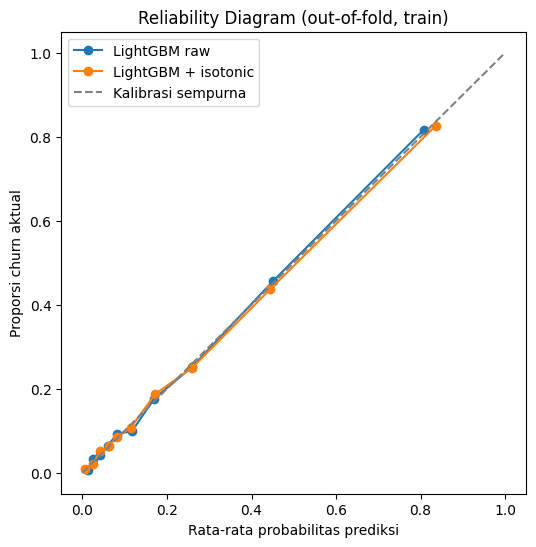

In [48]:
p_raw = cross_val_predict(best_lgbm, X_train_fe, y_train, cv=cv,
                          method='predict_proba', n_jobs=-1)[:, 1]
p_iso = cross_val_predict(cal_iso, X_train_fe, y_train, cv=cv,
                          method='predict_proba', n_jobs=-1)[:, 1]

print(f"Churn rate aktual       : {y_train.mean():.4f}")
print(f"Rata-rata prob raw      : {p_raw.mean():.4f}")
print(f"Rata-rata prob isotonic : {p_iso.mean():.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
for p, name in [(p_raw, 'LightGBM raw'), (p_iso, 'LightGBM + isotonic')]:
    frac_pos, mean_pred = calibration_curve(y_train, p, n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac_pos, marker='o', label=name)

ax.plot([0, 1], [0, 1], '--', color='gray', label='Kalibrasi sempurna')
ax.set_xlabel('Rata-rata probabilitas prediksi')
ax.set_ylabel('Proporsi churn aktual')
ax.set_title('Reliability Diagram (out-of-fold, train)')
ax.legend()
save_fig('04_reliability_diagram')
plt.show()

**Keputusan kalibrasi:** Isotonic dan sigmoid diuji dengan nested CV. Keduanya tidak memperbaiki Brier Score (0,1014 → 0,1017 / 0,1026), karena LightGBM tanpa pembobotan kelas sudah terkalibrasi baik. Model raw dipilih atas dasar parsimoni.

Langkah 4. Evaluasi final di Test Set

In [31]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

final_model = clone(best_lgbm)
final_model.fit(X_train_fe, y_train)

p_test = final_model.predict_proba(X_test_fe)[:, 1]

test_metrics = pd.DataFrame({
    'Metrik': ['PR-AUC', 'ROC-AUC', 'Brier'],
    'CV (train)': [0.7042, 0.8658, 0.1014],
    'Test': [average_precision_score(y_test, p_test),
             roc_auc_score(y_test, p_test),
             brier_score_loss(y_test, p_test)],
    'Asal tebak': [y_test.mean(), 0.5, y_test.mean() * (1 - y_test.mean())]
}).round(4)
test_metrics['Selisih (Test - CV)'] = (test_metrics['Test'] - test_metrics['CV (train)']).round(4)

print(f"Churn rate aktual test : {y_test.mean():.4f}")
print(f"Rata-rata prob test    : {p_test.mean():.4f}")
test_metrics

Churn rate aktual test : 0.2035
Rata-rata prob test    : 0.2041


,Metrik,CV (train),Test,Asal tebak,Selisih (Test - CV)
0,PR-AUC,0.7042,0.7247,0.2035,0.0205
1,ROC-AUC,0.8658,0.8705,0.5000,0.0047
2,Brier,0.1014,0.0980,0.1621,-0.0034


In [32]:
from sklearn.metrics import classification_report, confusion_matrix

pred_050 = (p_test > 0.50).astype(int)

print("Jumlah nasabah dengan p > 0,50:", pred_050.sum(), "dari", len(p_test))
print("\nConfusion matrix (baris = aktual, kolom = prediksi):")
print(confusion_matrix(y_test, pred_050))
print()
print(classification_report(y_test, pred_050, target_names=['Stay', 'Churn'], digits=4))

Jumlah nasabah dengan p > 0,50: 254 dari 2000

Confusion matrix (baris = aktual, kolom = prediksi):
[[1541   52]
 [ 205  202]]

              precision    recall  f1-score   support

        Stay     0.8826    0.9674    0.9230      1593
       Churn     0.7953    0.4963    0.6112       407

    accuracy                         0.8715      2000
   macro avg     0.8389    0.7318    0.7671      2000
weighted avg     0.8648    0.8715    0.8596      2000



**Evaluasi test:** PR-AUC 0,725, ROC-AUC 0,871, Brier 0,098. Skor test setara dengan CV, jadi model tidak overfitting. Rata-rata probabilitas (0,204) sama dengan churn aktual (0,204).

In [33]:
test_result = X_test_fe.copy()
test_result.insert(0, 'CustomerId', id_test.values)
test_result['Exited'] = y_test.values
test_result['p_churn'] = p_test

test_result.to_csv('test_predictions.csv', index=False)
test_result[['CustomerId', 'Balance', 'HasCrCard', 'Exited', 'p_churn']].head()

,CustomerId,Balance,HasCrCard,Exited,p_churn
5702,15749540,0.00,1,0,0.021702
3667,15807340,131023.76,0,0,0.071208
1617,15801062,0.00,0,0,0.034075
5673,15572801,139393.19,0,0,0.047016
4272,15600708,77826.80,1,0,0.090550


# Tahap 5: SHAP

Konsep singkat

SHAP membagi skor prediksi tiap nasabah menjadi kontribusi dari masing-masing fitur. Analoginya seperti struk belanja: “Skor dasar semua nasabah sekian, ditambah karena usianya 52, ditambah karena tidak aktif, dikurangi karena punya 2 produk, = skor akhir.”

Satu hal teknis: untuk LightGBM, SHAP bekerja dalam satuan log-odds, bukan probabilitas. Angka positif berarti mendorong ke arah churn, negatif berarti menahan nasabah tetap tinggal. Arahnya yang penting. Besarannya tidak bisa langsung dibaca sebagai “+X%”.

In [34]:
# !pip install shap   # jalankan hanya kalau import gagal
import shap

prep = final_model.named_steps['prep']
lgbm = final_model.named_steps['model']

X_test_tr = prep.transform(X_test_fe)
print("Shape setelah preprocessing:", X_test_tr.shape)
print("Kolom:", list(X_test_tr.columns))

explainer = shap.TreeExplainer(lgbm)
sv = explainer(X_test_tr)
print("Shape SHAP values:", sv.values.shape)

# Validasi: base + jumlah SHAP harus = prediksi model
logodds = sv.base_values + sv.values.sum(axis=1)
p_from_shap = 1 / (1 + np.exp(-logodds))
print("Selisih maks SHAP vs predict_proba:", np.abs(p_from_shap - p_test).max())

Shape setelah preprocessing: (2000, 15)
Kolom: ['Geography_Germany', 'Geography_Spain', 'Gender_Male', 'Balance_to_Salary', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Tenure_to_Age', 'Active_Engagement_Score', 'HasCrCard', 'IsActiveMember', 'Is_Zero_Balance']
Shape SHAP values: (2000, 15)
Selisih maks SHAP vs predict_proba: 2.1094237467877974e-15


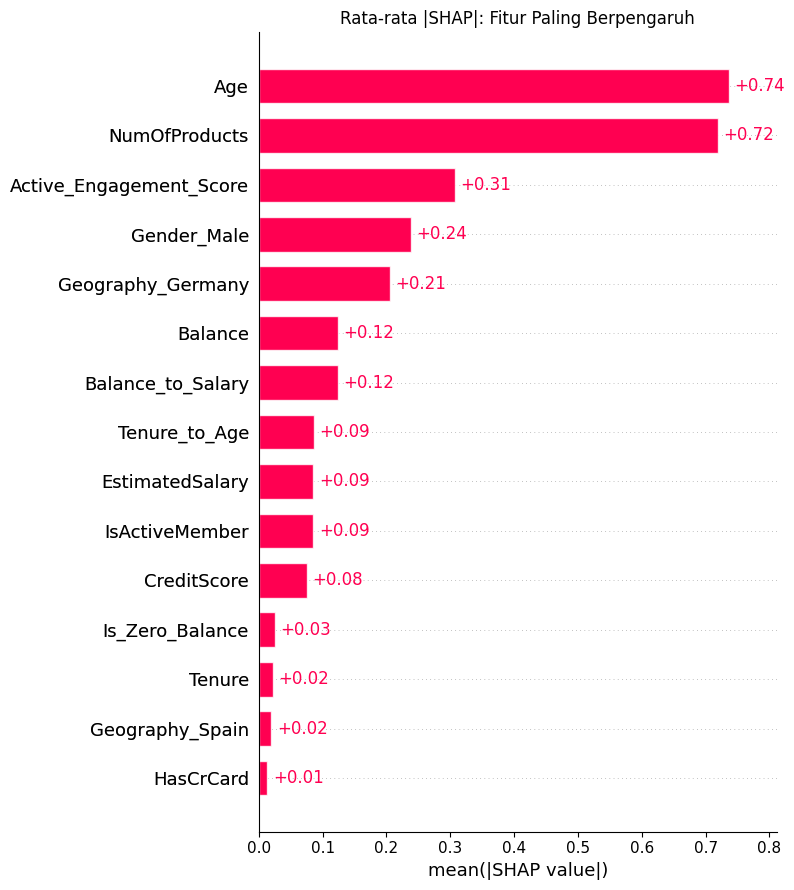

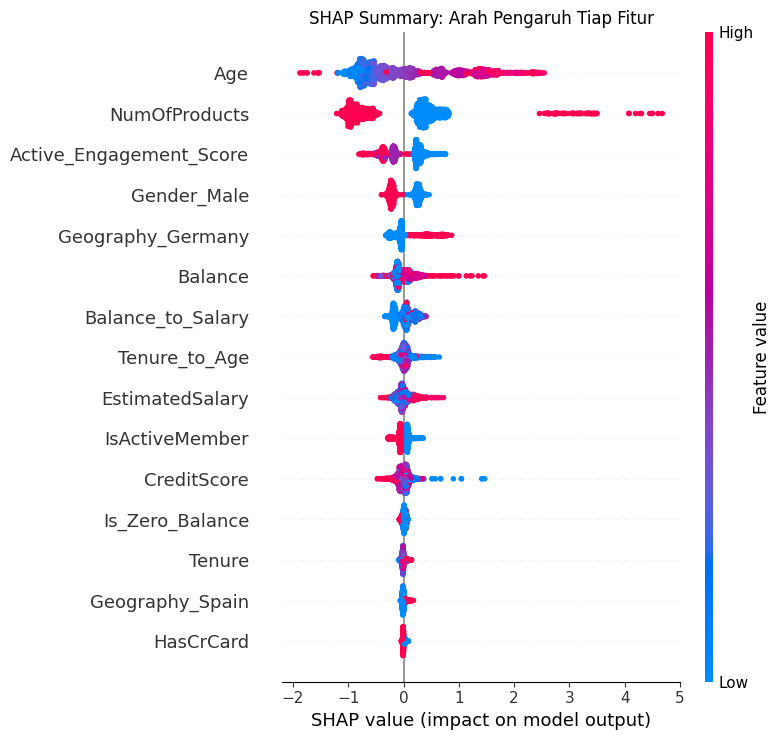

In [49]:
fig = plt.figure()
shap.plots.bar(sv, max_display=15, show=False)
plt.title('Rata-rata |SHAP|: Fitur Paling Berpengaruh')
plt.tight_layout()
plt.show()

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP Summary: Arah Pengaruh Tiap Fitur')
plt.tight_layout()
save_fig('05_shap_beeswarm')
plt.show()

**Global:** Pendorong utama churn adalah usia, jumlah produk, keterikatan aktif, jenis kelamin (perempuan lebih berisiko), dan Jerman, konsisten dengan EDA. IsActiveMember tampak lemah karena informasinya terbagi dengan Active_Engagement_Score. Balance_to_Salary dan EstimatedSalary hanya berpengaruh kecil, sesuai dugaan bahwa EstimatedSalary di dataset ini tidak informatif.

      CustomerId Geography Gender  Age  Tenure    Balance  NumOfProducts  IsActiveMember  HasCrCard  Exited  p_churn
501     15703793   Germany   Male   58       2 133,745.44              4               0          1       1     1.00
1208    15605279    France   Male   50       9       0.00              4               1          1       1     0.96


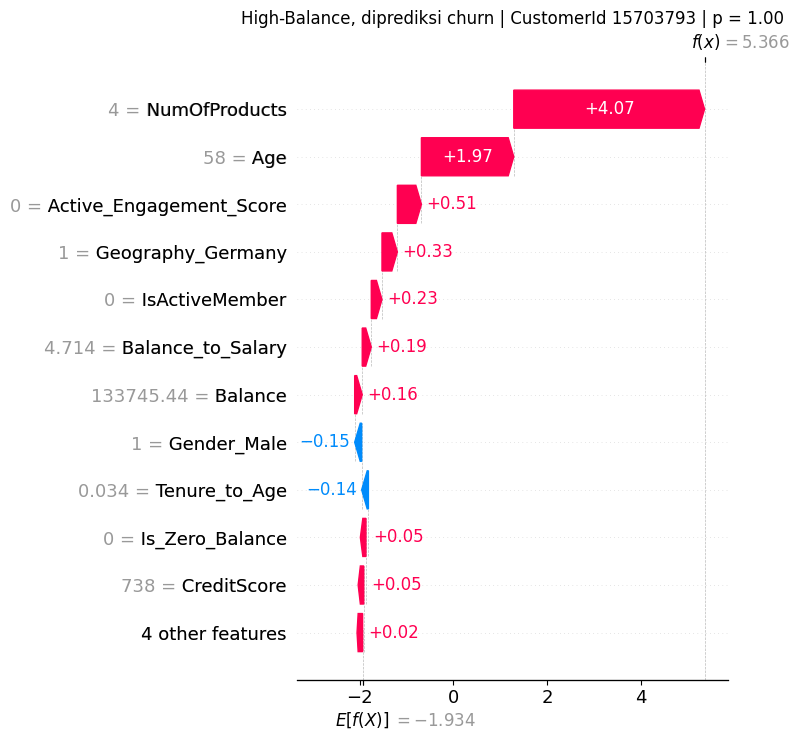

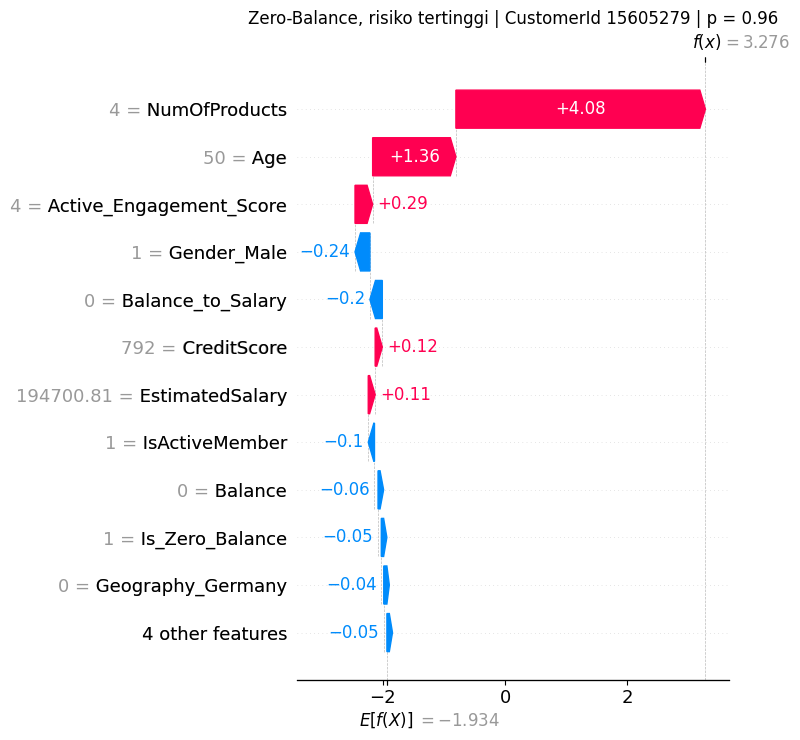

In [55]:
tr = test_result.reset_index(drop=True)

hb_pos = tr[(tr['Balance'] > 120000) & (tr['p_churn'] > 0.5)]['p_churn'].idxmax()
lb_pos = tr[tr['Balance'] == 0]['p_churn'].idxmax()

cols_show = ['CustomerId', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
             'NumOfProducts', 'IsActiveMember', 'HasCrCard', 'Exited', 'p_churn']
print(tr.loc[[hb_pos, lb_pos], cols_show].to_string())

for pos, judul in [(hb_pos, 'High-Balance, diprediksi churn'),
                   (lb_pos, 'Zero-Balance, risiko tertinggi')]:
    shap.plots.waterfall(sv[pos], max_display=12, show=False)
    plt.title(f'{judul} | CustomerId {tr.loc[pos, "CustomerId"]} | p = {tr.loc[pos, "p_churn"]:.2f}')
    plt.tight_layout()
    save_fig('08_profit_curve')
    plt.show()

**Lokal:** Dua nasabah dengan profil risiko hampir identik (perempuan, 56–57 tahun, tidak aktif, 1 produk, p ≈ 0,96). Yang satu bersaldo €163.146, yang lain €0. Di Tahap 6, keduanya mendapat keputusan yang berlawanan.

      CustomerId Geography  Gender  Age  Tenure    Balance  NumOfProducts  IsActiveMember  HasCrCard  Exited  p_churn
615     15679249   Germany  Female   57       4 163,146.46              1               0          1       1     0.96
1174    15707637    France  Female   56       1       0.00              1               0          1       1     0.96


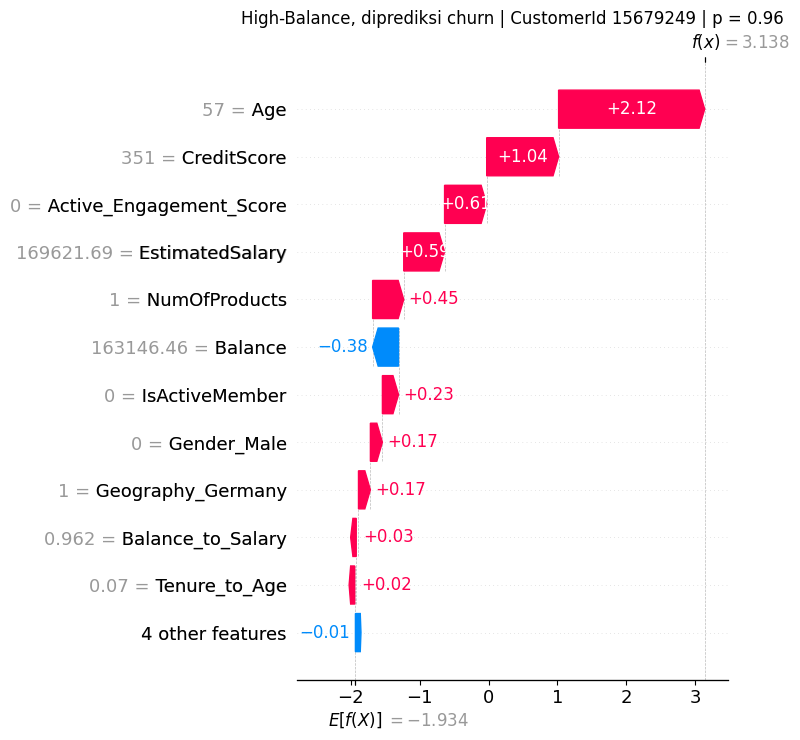

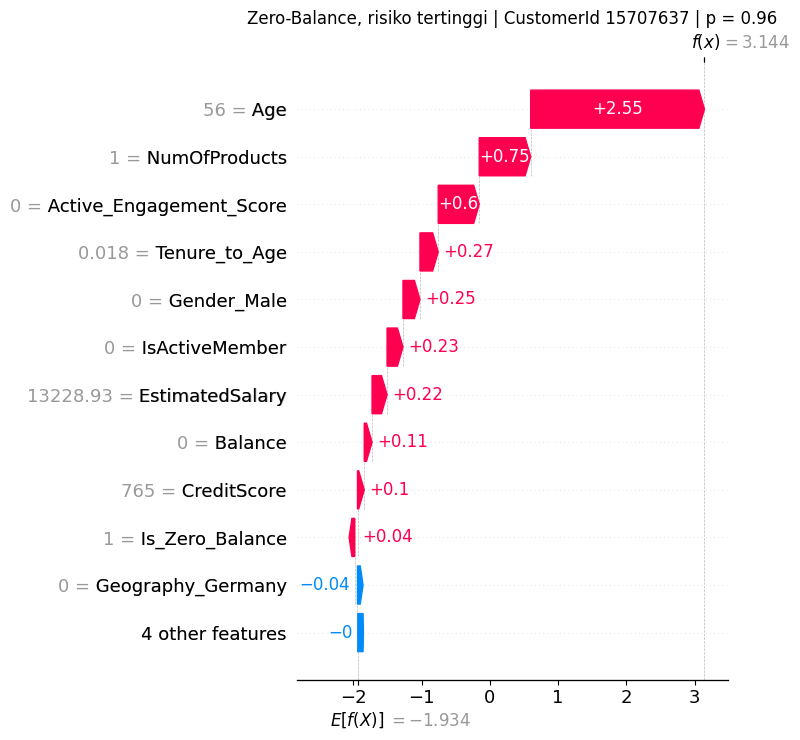

In [51]:
base = tr[tr['NumOfProducts'] <= 2]

hb_pos = base[(base['Balance'] > 120000) & (base['p_churn'] > 0.5)]['p_churn'].idxmax()
lb_pos = base[base['Balance'] == 0]['p_churn'].idxmax()

print(tr.loc[[hb_pos, lb_pos], cols_show].to_string())

for pos, judul in [(hb_pos, 'High-Balance, diprediksi churn'),
                   (lb_pos, 'Zero-Balance, risiko tertinggi')]:
    shap.plots.waterfall(sv[pos], max_display=12, show=False)
    plt.title(f'{judul} | CustomerId {tr.loc[pos, "CustomerId"]} | p = {tr.loc[pos, "p_churn"]:.2f}')
    plt.tight_layout()
    save_fig('09_sensitivity_heatmap')
    plt.show()

In [38]:
SAVE_RATE = 0.40
COST      = 150
NIM       = 0.03
CC_FEE    = 50
BUDGET    = 15000

df6 = test_result.reset_index(drop=True).copy()

df6['Revenue']   = df6['Balance'] * NIM + df6['HasCrCard'] * CC_FEE
df6['ENV']       = df6['p_churn'] * SAVE_RATE * df6['Revenue'] - COST
df6['ENV_brief'] = (df6['p_churn'] * SAVE_RATE * (df6['Revenue'] - COST)
                    - (1 - df6['p_churn']) * COST)

df6[['Revenue', 'ENV', 'ENV_brief']].describe().round(2)

,Revenue,ENV,ENV_brief
count,2000.00,2000.00,2000.00
mean,2341.76,78.11,96.48
std,1883.82,350.64,367.77
min,0.00,-150.00,-149.48
25%,50.00,-149.08,-140.28
50%,2966.27,-57.37,-49.41
75%,3875.54,118.85,136.62
max,7526.94,2699.41,2784.58


In [39]:
def evaluate_strategy(name, mask):
    t = df6[mask]
    cost  = len(t) * COST
    saved = (t['Exited'] * SAVE_RATE * t['Revenue']).sum()
    return {
        'Strategi': name,
        'Ditarget': len(t),
        'Saldo 0 ditarget': int((t['Balance'] == 0).sum()),
        'Churner kena': int(t['Exited'].sum()),
        'Biaya promo (€)': cost,
        'Revenue selamat (€)': saved,
        'Net Profit (€)': saved - cost,
        'ROI': (saved - cost) / cost if cost > 0 else np.nan
    }

n_budget = int(BUDGET // COST)
none     = np.zeros(len(df6), dtype=bool)

strategies = [
    ('A. Tanpa intervensi',          none),
    ('B. Threshold p > 0,50',        (df6['p_churn'] > 0.50).values),
    ('C. ENV > 0 (rumus koreksi)',   (df6['ENV'] > 0).values),
    ('C*. ENV_brief > 0 (rumus brief)', (df6['ENV_brief'] > 0).values),
    (f'B-budget. Top {n_budget} p_churn',
        df6.index.isin(df6.nlargest(n_budget, 'p_churn').index)),
    (f'C-budget. Top {n_budget} ENV (>0)',
        df6.index.isin(df6[df6['ENV'] > 0].nlargest(n_budget, 'ENV').index)),
]

strat_table = pd.DataFrame([evaluate_strategy(n, m) for n, m in strategies])

lost_total = (df6['Exited'] * df6['Revenue']).sum()
print(f"Total revenue tahunan yang hilang jika tanpa intervensi: €{lost_total:,.0f}")
print(f"Batas maksimal yang bisa diselamatkan (semua churner, save rate 40%): €{lost_total * SAVE_RATE:,.0f}")

pd.options.display.float_format = '{:,.2f}'.format
strat_table

Total revenue tahunan yang hilang jika tanpa intervensi: €1,115,750
Batas maksimal yang bisa diselamatkan (semua churner, save rate 40%): €446,300


,Strategi,Ditarget,Saldo 0 ditarget,Churner kena,Biaya promo (€),Revenue selamat (€),Net Profit (€),ROI
0,A. Tanpa intervensi,0,0,0,0,0.00,0.00,NaN
1,"B. Threshold p > 0,50",254,59,202,38100,"228,503.30","190,403.30",5.00
2,C. ENV > 0 (rumus koreksi),768,0,263,115200,"396,118.17","280,918.17",2.44
3,C*. ENV_brief > 0 (rumus brief),793,0,267,118950,"401,987.89","283,037.89",2.38
4,B-budget. Top 100 p_churn,100,22,94,15000,"109,555.56","94,555.56",6.30
5,C-budget. Top 100 ENV (>0),100,0,86,15000,"144,858.16","129,858.16",8.66


**Hasil:** Strategi C menghasilkan €280.918, naik 47,5% dibanding Strategi B (€190.403), tanpa satu pun promo ke rekening bersaldo nol. Dengan anggaran yang sama (€15.000), pemeringkatan berdasarkan ENV menghasilkan €129.858 vs €94.556 (+37,3%), walaupun menangkap churner lebih sedikit (86 vs 94).

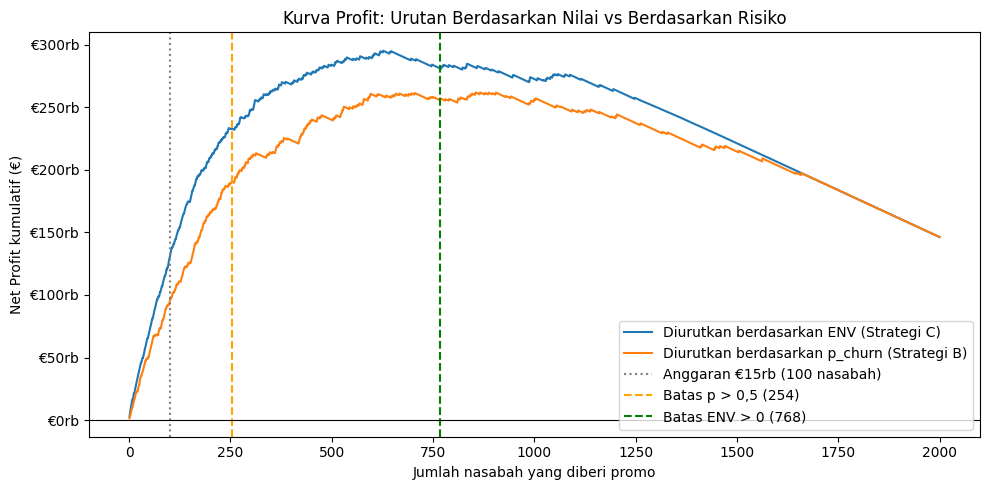

Puncak kurva ENV    : €295,132 di nasabah ke-627
Puncak kurva p_churn: €261,811 di nasabah ke-866


In [52]:
def cum_profit(order_col):
    d = df6.sort_values(order_col, ascending=False)
    gain = d['Exited'] * SAVE_RATE * d['Revenue'] - COST
    return gain.cumsum().values

x = np.arange(1, len(df6) + 1)
cp_env = cum_profit('ENV')
cp_p   = cum_profit('p_churn')

n_env_pos = int((df6['ENV'] > 0).sum())
n_p50     = int((df6['p_churn'] > 0.5).sum())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, cp_env, label='Diurutkan berdasarkan ENV (Strategi C)')
ax.plot(x, cp_p,   label='Diurutkan berdasarkan p_churn (Strategi B)')
ax.axvline(n_budget,  ls=':',  color='gray',   label=f'Anggaran €15rb ({n_budget} nasabah)')
ax.axvline(n_p50,     ls='--', color='orange', label=f'Batas p > 0,5 ({n_p50})')
ax.axvline(n_env_pos, ls='--', color='green',  label=f'Batas ENV > 0 ({n_env_pos})')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Jumlah nasabah yang diberi promo')
ax.set_ylabel('Net Profit kumulatif (€)')
ax.set_title('Kurva Profit: Urutan Berdasarkan Nilai vs Berdasarkan Risiko')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'€{v/1000:,.0f}rb'))
ax.legend()
plt.tight_layout()
save_fig('08_profit_curve')
plt.show()

print(f"Puncak kurva ENV    : €{cp_env.max():,.0f} di nasabah ke-{cp_env.argmax() + 1}")
print(f"Puncak kurva p_churn: €{cp_p.max():,.0f} di nasabah ke-{cp_p.argmax() + 1}")

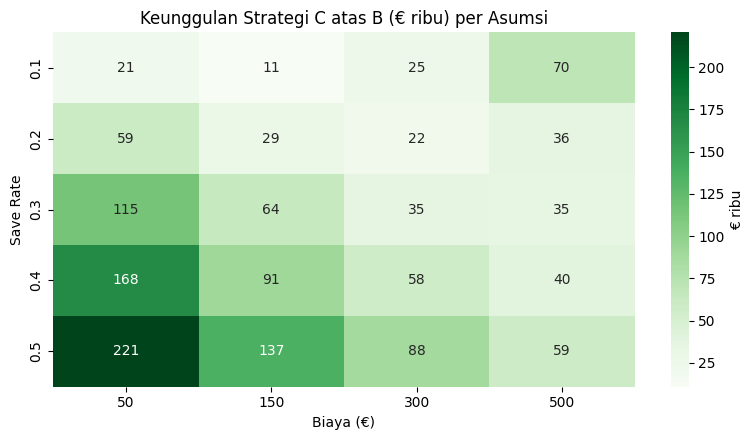

,Save Rate,Biaya (€),Profit B (€),Profit C (€),Ditarget C,C - B (€),B rugi?,C rugi?
0,0.10,50,"44,426.00","65,595.00",634,"21,170.00",False,False
1,0.10,150,"19,026.00","29,903.00",236,"10,877.00",False,False
2,0.10,300,"-19,074.00","5,518.00",73,"24,592.00",True,False
3,0.10,500,"-69,874.00",465.00,3,"70,339.00",True,False
4,0.20,50,"101,552.00","160,770.00",965,"59,218.00",False,False
5,0.20,150,"76,152.00","105,027.00",467,"28,876.00",False,False
6,0.20,300,"38,052.00","59,805.00",236,"21,754.00",False,False
7,0.20,500,"-12,748.00","23,645.00",113,"36,394.00",True,False
8,0.30,50,"158,677.00","273,916.00",1122,"115,238.00",False,False
9,0.30,150,"133,277.00","196,786.00",634,"63,509.00",False,False


In [56]:
def run_scenario(save_rate, cost):
    rev = df6['Revenue']
    env = df6['p_churn'] * save_rate * rev - cost
    gain = df6['Exited'] * save_rate * rev - cost
    mask_b = df6['p_churn'] > 0.5
    mask_c = env > 0
    return {
        'Save Rate': save_rate, 'Biaya (€)': cost,
        'Profit B (€)': gain[mask_b].sum(),
        'Profit C (€)': gain[mask_c].sum(),
        'Ditarget C': int(mask_c.sum()),
        'C - B (€)': gain[mask_c].sum() - gain[mask_b].sum()
    }

sens = pd.DataFrame([run_scenario(s, c)
                     for s in [0.10, 0.20, 0.30, 0.40, 0.50]
                     for c in [50, 150, 300, 500]])

pivot_diff = sens.pivot(index='Save Rate', columns='Biaya (€)', values='C - B (€)')

plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot_diff / 1000, annot=True, fmt=',.0f', cmap='Greens', cbar_kws={'label': '€ ribu'})
plt.title('Keunggulan Strategi C atas B (€ ribu) per Asumsi')
plt.tight_layout()
save_fig('09_sensitivity_heatmap')
plt.show()

money = ['Profit B (€)', 'Profit C (€)', 'C - B (€)']
sens_disp = sens.copy()
sens_disp[money] = sens_disp[money].round(0)
sens_disp['B rugi?'] = sens_disp['Profit B (€)'] < 0
sens_disp['C rugi?'] = sens_disp['Profit C (€)'] < 0
sens_disp

**Sensitivitas:** C unggul atas B di 20 dari 20 skenario. B rugi di 3 skenario pesimis (hingga −€69.874), sedangkan C tidak pernah rugi karena jumlah target menyesuaikan otomatis dengan ekonomi kampanye.

In [42]:
priority = df6[df6['ENV'] > 0].sort_values('ENV', ascending=False).copy()
priority['Rank'] = np.arange(1, len(priority) + 1)
priority['Masuk_Budget_15rb'] = priority['Rank'] <= n_budget

export_cols = ['Rank', 'CustomerId', 'Geography', 'Gender', 'Age', 'Balance',
               'NumOfProducts', 'IsActiveMember', 'HasCrCard',
               'p_churn', 'Revenue', 'ENV', 'Masuk_Budget_15rb']

priority[export_cols].round(4).to_csv('priority_list.csv', index=False)

print("Total nasabah prioritas (ENV > 0):", len(priority))
print("Masuk anggaran €15rb             :", priority['Masuk_Budget_15rb'].sum())
print("Total ENV (expected) seluruh daftar: €{:,.0f}".format(priority['ENV'].sum()))
priority[export_cols].head(10)

Total nasabah prioritas (ENV > 0): 768
Masuk anggaran €15rb             : 100
Total ENV (expected) seluruh daftar: €295,034


,Rank,CustomerId,Geography,Gender,Age,Balance,NumOfProducts,IsActiveMember,HasCrCard,p_churn,Revenue,ENV,Masuk_Budget_15rb
654,1,15757408,Spain,Male,38,"250,898.09",3,1,0,0.95,"7,526.94","2,699.41",True
1900,2,15594408,Spain,Female,48,"213,146.20",1,0,1,0.86,"6,444.39","2,064.69",True
1825,3,15811588,Spain,Female,53,"187,602.18",1,0,1,0.93,"5,678.07","1,952.10",True
615,4,15679249,Germany,Female,57,"163,146.46",1,0,1,0.96,"4,944.39","1,745.52",True
1298,5,15775318,Spain,Female,51,"154,962.99",3,1,0,0.97,"4,648.89","1,656.62",True
1585,6,15815490,Germany,Male,40,"164,948.98",3,0,0,0.89,"4,948.47","1,607.28",True
875,7,15781272,France,Male,50,"149,713.61",3,1,1,0.96,"4,541.41","1,588.49",True
324,8,15740442,France,Male,51,"186,825.57",1,0,1,0.77,"5,654.77","1,585.24",True
1050,9,15616152,France,Female,47,"185,513.67",1,0,1,0.76,"5,615.41","1,567.26",True
1297,10,15764604,France,Female,35,"164,769.02",3,0,1,0.85,"4,993.07","1,554.08",True


In [57]:
import importlib.metadata as md

pkgs = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn',
        'lightgbm', 'shap', 'statsmodels', 'scipy']
with open('requirements.txt', 'w') as f:
    for p in pkgs:
        f.write(f"{p}=={md.version(p)}\n")

print(open('requirements.txt').read())

pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
lightgbm==4.6.0
shap==0.54.1
statsmodels==0.15.0
scipy==1.16.3

